In [1]:
print("Zimbabwe Mobile Money Fraud Detection Project")
print("Python is working!")

Zimbabwe Mobile Money Fraud Detection Project
Python is working!


In [2]:
from pathlib import Path

downloads = Path.home() / "Downloads"

print("Checking Downloads folder...")
print("Folder exists:", downloads.exists())

if downloads.exists():
    for file in downloads.glob("*.csv"):
        print(file.name)

Checking Downloads folder...
Folder exists: True


In [3]:
from pathlib import Path

downloads = Path.home() / "Downloads"

print("Searching for the PaySim dataset...")

for file in downloads.rglob("*.csv"):
    print(file)

Searching for the PaySim dataset...
C:\Users\primr\Downloads\Zimbabwe_Fraud_Detection\data\PS_20174392719_1491204439457_log.csv


In [4]:
import pandas as pd
from pathlib import Path

file_path = Path.home() / "Downloads" / "Zimbabwe_Fraud_Detection" / "data" / "PS_20174392719_1491204439457_log.csv"

df_sample = pd.read_csv(file_path, nrows=5)

print("First 5 rows:")
display(df_sample)

print("Column names:")
print(df_sample.columns.tolist())

First 5 rows:


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


Column names:
['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig', 'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud', 'isFlaggedFraud']


In [5]:

from pathlib import Path
import os

file_path = (
    Path.home()
    / "Downloads"
    / "Zimbabwe_Fraud_Detection"
    / "data"
    / "PS_20174392719_1491204439457_log.csv"
)

print("Dataset file exists:", file_path.exists())

if file_path.exists():
    print("File size (MB):", round(os.path.getsize(file_path) / (1024 * 1024), 2))


Dataset file exists: True
File size (MB): 470.67


In [6]:

import pandas as pd

df_sample = pd.read_csv(file_path, nrows=1000)

print("Sample shape:", df_sample.shape)

print("\nColumn names:")
print(df_sample.columns.tolist())

print("\nData types:")
print(df_sample.dtypes)

print("\nMissing values in the sample:")
print(df_sample.isnull().sum())


Sample shape: (1000, 11)

Column names:
['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig', 'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud', 'isFlaggedFraud']

Data types:
step                int64
type                  str
amount            float64
nameOrig              str
oldbalanceOrg     float64
newbalanceOrig    float64
nameDest              str
oldbalanceDest    float64
newbalanceDest    float64
isFraud             int64
isFlaggedFraud      int64
dtype: object

Missing values in the sample:
step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64


In [7]:

if "isFraud" in df_sample.columns:
    print("Fraud target column found!")
    print("\nFraud labels in the sample:")
    print(df_sample["isFraud"].value_counts(dropna=False))
else:
    print("isFraud was not found. Check the column names above.")


Fraud target column found!

Fraud labels in the sample:
isFraud
0    991
1      9
Name: count, dtype: int64


In [8]:

import pandas as pd

total_rows = 0
total_fraud = 0
total_legitimate = 0
chunk_size = 100_000

print("Checking the full dataset in small batches...")

for chunk in pd.read_csv(file_path, chunksize=chunk_size):
    total_rows += len(chunk)

    if "isFraud" in chunk.columns:
        counts = chunk["isFraud"].value_counts()
        total_fraud += int(counts.get(1, 0))
        total_legitimate += int(counts.get(0, 0))
    else:
        raise ValueError("The isFraud column was not found.")

print("\nDATASET SUMMARY")
print("-------------------------")
print("Total transactions:", f"{total_rows:,}")
print("Fraudulent transactions:", f"{total_fraud:,}")
print("Legitimate transactions:", f"{total_legitimate:,}")

if total_rows > 0:
    print("Fraud percentage:", f"{total_fraud / total_rows * 100:.4f}%")
    print("Legitimate percentage:", f"{total_legitimate / total_rows * 100:.4f}%")


Checking the full dataset in small batches...

DATASET SUMMARY
-------------------------
Total transactions: 6,362,620
Fraudulent transactions: 8,213
Legitimate transactions: 6,354,407
Fraud percentage: 0.1291%
Legitimate percentage: 99.8709%


In [9]:

import pandas as pd

type_summary = pd.DataFrame()

print("Counting transactions by type...")

for chunk in pd.read_csv(
    file_path,
    usecols=["type", "isFraud"],
    chunksize=100_000
):
    batch_summary = pd.crosstab(
        chunk["type"],
        chunk["isFraud"]
    )

    type_summary = type_summary.add(
        batch_summary,
        fill_value=0
    )

type_summary = type_summary.fillna(0).astype("int64")

type_summary = type_summary.rename(
    columns={
        0: "Legitimate",
        1: "Fraudulent"
    }
)

type_summary["Total"] = type_summary.sum(axis=1)

type_summary["Fraud_Percentage"] = (
    type_summary["Fraudulent"]
    / type_summary["Total"]
    * 100
).round(4)

print("\nTRANSACTIONS BY TYPE")
display(type_summary.sort_values("Total", ascending=False))


Counting transactions by type...

TRANSACTIONS BY TYPE


isFraud,Legitimate,Fraudulent,Total,Fraud_Percentage
type,,,,
CASH_OUT,2233384,4116,2237500,0.1840
PAYMENT,2151495,0,2151495,0.0000
CASH_IN,1399284,0,1399284,0.0000
TRANSFER,528812,4097,532909,0.7688
DEBIT,41432,0,41432,0.0000


In [10]:

import pandas as pd

fraud_parts = []
legitimate_sample = pd.DataFrame()
sample_size = 200_000

print("Building the development sample...")

for chunk in pd.read_csv(file_path, chunksize=100_000):
    fraud = chunk[chunk["isFraud"] == 1]
    fraud_parts.append(fraud)

    legitimate = chunk[chunk["isFraud"] == 0]

    combined = pd.concat(
        [legitimate_sample, legitimate],
        ignore_index=True
    )

    legitimate_sample = combined.sample(
        n=min(sample_size, len(combined)),
        random_state=42
    )

fraud_df = pd.concat(fraud_parts, ignore_index=True)

model_df = pd.concat(
    [fraud_df, legitimate_sample],
    ignore_index=True
)

model_df = model_df.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

print("\nSAMPLE SUMMARY")
print("Total rows:", f"{len(model_df):,}")
print("Fraudulent:", int((model_df["isFraud"] == 1).sum()))
print("Legitimate:", int((model_df["isFraud"] == 0).sum()))
print("Fraud percentage:", round(model_df["isFraud"].mean() * 100, 2), "%")
print("Sample ready!")



Building the development sample...

SAMPLE SUMMARY
Total rows: 208,213
Fraudulent: 8213
Legitimate: 200000
Fraud percentage: 3.94 %
Sample ready!


In [11]:

# Select features for the first model
feature_columns = [
    "step",
    "type",
    "amount",
    "oldbalanceOrg",
    "oldbalanceDest"
]

X = model_df[feature_columns].copy()
y = model_df["isFraud"].copy()

print("Features and target prepared!")
print("\nFeature columns:")
print(X.columns.tolist())

print("\nFeatures shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget counts:")
print(y.value_counts())


Features and target prepared!

Feature columns:
['step', 'type', 'amount', 'oldbalanceOrg', 'oldbalanceDest']

Features shape: (208213, 5)
Target shape: (208213,)

Target counts:
isFraud
0    200000
1      8213
Name: count, dtype: int64


In [13]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("DATA SPLIT COMPLETE")
print("-------------------------")
print("Training rows:", f"{len(X_train):,}")
print("Testing rows:", f"{len(X_test):,}")

print("\nFraud cases in training set:", int(y_train.sum()))
print("Fraud cases in testing set:", int(y_test.sum()))

print("\nTraining fraud percentage:",
      round(y_train.mean() * 100, 2), "%")

print("Testing fraud percentage:",
      round(y_test.mean() * 100, 2), "%")


DATA SPLIT COMPLETE
-------------------------
Training rows: 166,570
Testing rows: 41,643

Fraud cases in training set: 6570
Fraud cases in testing set: 1643

Training fraud percentage: 3.94 %
Testing fraud percentage: 3.95 %


In [14]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

numeric_features = [
    "step",
    "amount",
    "oldbalanceOrg",
    "oldbalanceDest"
]

categorical_features = ["type"]

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), numeric_features),
        ("categorical", OneHotEncoder(handle_unknown="ignore"),
         categorical_features)
    ]
)

logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

print("Training Logistic Regression...")

logistic_model.fit(X_train, y_train)

print("Model training completed!")


Training Logistic Regression...
Model training completed!


In [15]:

y_pred = logistic_model.predict(X_test)
y_prob = logistic_model.predict_proba(X_test)[:, 1]

print("CLASSIFICATION REPORT")
print("-------------------------")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Legitimate", "Fraud"],
    digits=4,
    zero_division=0
))

print("CONFUSION MATRIX")
print("-------------------------")
print(confusion_matrix(y_test, y_pred))

print("\nROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))
print(
    "Average precision:",
    round(average_precision_score(y_test, y_prob), 4)
)


CLASSIFICATION REPORT
-------------------------
              precision    recall  f1-score   support

  Legitimate     0.9959    0.9062    0.9490     40000
       Fraud     0.2848    0.9093    0.4338      1643

    accuracy                         0.9063     41643
   macro avg     0.6404    0.9078    0.6914     41643
weighted avg     0.9679    0.9063    0.9286     41643

CONFUSION MATRIX
-------------------------
[[36249  3751]
 [  149  1494]]

ROC-AUC: 0.9748
Average precision: 0.7882


In [16]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        max_depth=15,
        min_samples_leaf=2,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    ))
])

print("Training Random Forest...")

rf_model.fit(X_train, y_train)

print("Random Forest training completed!")


Training Random Forest...
Random Forest training completed!


In [17]:

rf_pred = rf_model.predict(X_test)
rf_prob = rf_model.predict_proba(X_test)[:, 1]

print("RANDOM FOREST CLASSIFICATION REPORT")
print("-----------------------------------")
print(classification_report(
    y_test,
    rf_pred,
    target_names=["Legitimate", "Fraud"],
    digits=4,
    zero_division=0
))

print("CONFUSION MATRIX")
print(confusion_matrix(y_test, rf_pred))

print("\nROC-AUC:", round(roc_auc_score(y_test, rf_prob), 4))
print(
    "Average precision:",
    round(average_precision_score(y_test, rf_prob), 4)
)


RANDOM FOREST CLASSIFICATION REPORT
-----------------------------------
              precision    recall  f1-score   support

  Legitimate     0.9990    0.9898    0.9944     40000
       Fraud     0.7976    0.9763    0.8779      1643

    accuracy                         0.9893     41643
   macro avg     0.8983    0.9830    0.9362     41643
weighted avg     0.9911    0.9893    0.9898     41643

CONFUSION MATRIX
[[39593   407]
 [   39  1604]]

ROC-AUC: 0.9993
Average precision: 0.9863


In [18]:

import pandas as pd
import numpy as np

rng = np.random.default_rng(42)

fraud_parts = []
legitimate_sample = pd.DataFrame()
sample_size = 200_000

print("Creating a uniformly sampled development dataset...")

for chunk in pd.read_csv(file_path, chunksize=100_000):
    fraud = chunk[chunk["isFraud"] == 1]
    fraud_parts.append(fraud)

    legitimate = chunk[chunk["isFraud"] == 0].copy()

    if not legitimate.empty:
        legitimate["_sample_key"] = rng.random(len(legitimate))

        candidates = pd.concat(
            [legitimate_sample, legitimate],
            ignore_index=True
        )

        legitimate_sample = candidates.nsmallest(
            sample_size, "_sample_key"
        ).reset_index(drop=True)

fraud_df = pd.concat(fraud_parts, ignore_index=True)

legitimate_sample = legitimate_sample.drop(
    columns=["_sample_key"]
)

model_df = pd.concat(
    [fraud_df, legitimate_sample],
    ignore_index=True
)

model_df = model_df.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

print("\nCORRECTED SAMPLE SUMMARY")
print("Total rows:", f"{len(model_df):,}")
print("Fraudulent:", int(model_df["isFraud"].sum()))
print("Legitimate:", int((model_df["isFraud"] == 0).sum()))
print(
    "Fraud percentage:",
    round(model_df["isFraud"].mean() * 100, 4), "%"
)


Creating a uniformly sampled development dataset...

CORRECTED SAMPLE SUMMARY
Total rows: 208,213
Fraudulent: 8213
Legitimate: 200000
Fraud percentage: 3.9445 %


In [19]:

from sklearn.model_selection import train_test_split

feature_columns = [
    "step",
    "type",
    "amount",
    "oldbalanceOrg",
    "oldbalanceDest"
]

X = model_df[feature_columns].copy()
y = model_df["isFraud"].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("TRAINING AND TESTING SUMMARY")
print("-" * 35)
print("Training rows:", f"{len(X_train):,}")
print("Testing rows:", f"{len(X_test):,}")
print("Training fraud cases:", int(y_train.sum()))
print("Testing fraud cases:", int(y_test.sum()))
print("Training fraud rate:", round(y_train.mean() * 100, 4), "%")
print("Testing fraud rate:", round(y_test.mean() * 100, 4), "%")


TRAINING AND TESTING SUMMARY
-----------------------------------
Training rows: 166,570
Testing rows: 41,643
Training fraud cases: 6570
Testing fraud cases: 1643
Training fraud rate: 3.9443 %
Testing fraud rate: 3.9454 %


In [20]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

numeric_features = [
    "step",
    "amount",
    "oldbalanceOrg",
    "oldbalanceDest"
]

categorical_features = ["type"]

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), numeric_features),
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ]
)

logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                class_weight="balanced",
                max_iter=1000,
                random_state=42
            )
        )
    ]
)

print("Training Logistic Regression...")
logistic_model.fit(X_train, y_train)

print("Logistic Regression training completed successfully!")


Training Logistic Regression...
Logistic Regression training completed successfully!


Evaluating Logistic Regression...

CLASSIFICATION REPORT
              precision    recall  f1-score   support

  Legitimate     0.9960    0.9000    0.9456     40000
       Fraud     0.2724    0.9117    0.4195      1643

    accuracy                         0.9004     41643
   macro avg     0.6342    0.9059    0.6825     41643
weighted avg     0.9674    0.9004    0.9248     41643

ROC-AUC: 0.9696
Average Precision: 0.7241

CONFUSION MATRIX
[[35999  4001]
 [  145  1498]]


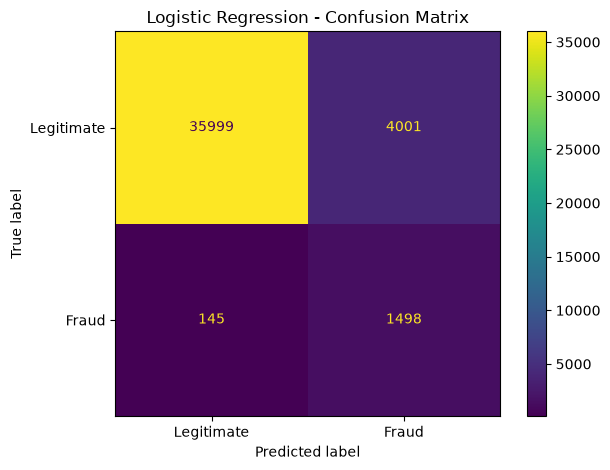

In [22]:

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

print("Evaluating Logistic Regression...\n")

y_pred_log = logistic_model.predict(X_test)
y_prob_log = logistic_model.predict_proba(X_test)[:, 1]

print("CLASSIFICATION REPORT")
print(classification_report(
    y_test,
    y_pred_log,
    target_names=["Legitimate", "Fraud"],
    digits=4
))

print("ROC-AUC:", round(roc_auc_score(y_test, y_prob_log), 4))
print("Average Precision:", round(
    average_precision_score(y_test, y_prob_log), 4
))

cm_log = confusion_matrix(y_test, y_pred_log)

print("\nCONFUSION MATRIX")
print(cm_log)

ConfusionMatrixDisplay(
    confusion_matrix=cm_log,
    display_labels=["Legitimate", "Fraud"]
).plot(values_format="d")

plt.title("Logistic Regression - Confusion Matrix")
plt.tight_layout()
plt.show()


In [23]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

rf_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=100,
                max_depth=15,
                min_samples_leaf=2,
                class_weight="balanced_subsample",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

print("Training Random Forest...")
rf_model.fit(X_train, y_train)

print("Random Forest training completed successfully!")


Training Random Forest...
Random Forest training completed successfully!


Evaluating Random Forest...

CLASSIFICATION REPORT
              precision    recall  f1-score   support

  Legitimate     0.9992    0.9832    0.9911     40000
       Fraud     0.7055    0.9811    0.8208      1643

    accuracy                         0.9831     41643
   macro avg     0.8523    0.9822    0.9060     41643
weighted avg     0.9876    0.9831    0.9844     41643

ROC-AUC: 0.9984
Average Precision: 0.9767

CONFUSION MATRIX
[[39327   673]
 [   31  1612]]


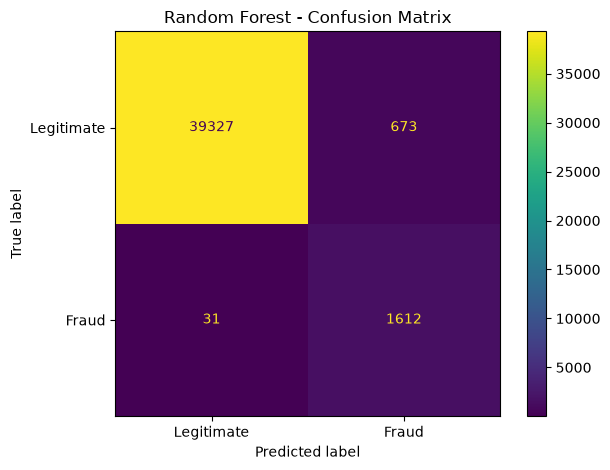

In [24]:

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

print("Evaluating Random Forest...\n")

y_pred_rf = rf_model.predict(X_test)
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

print("CLASSIFICATION REPORT")
print(classification_report(
    y_test,
    y_pred_rf,
    target_names=["Legitimate", "Fraud"],
    digits=4
))

print("ROC-AUC:", round(roc_auc_score(y_test, y_prob_rf), 4))
print("Average Precision:", round(
    average_precision_score(y_test, y_prob_rf), 4
))

cm_rf = confusion_matrix(y_test, y_pred_rf)

print("\nCONFUSION MATRIX")
print(cm_rf)

ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=["Legitimate", "Fraud"]
).plot(values_format="d")

plt.title("Random Forest - Confusion Matrix")
plt.tight_layout()
plt.show()


MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Fraud Precision,Fraud Recall,Fraud F1-score,ROC-AUC,Average Precision
0,Logistic Regression,0.9004,0.2724,0.9117,0.4195,0.9696,0.7241
1,Random Forest,0.9831,0.7055,0.9811,0.8208,0.9984,0.9767


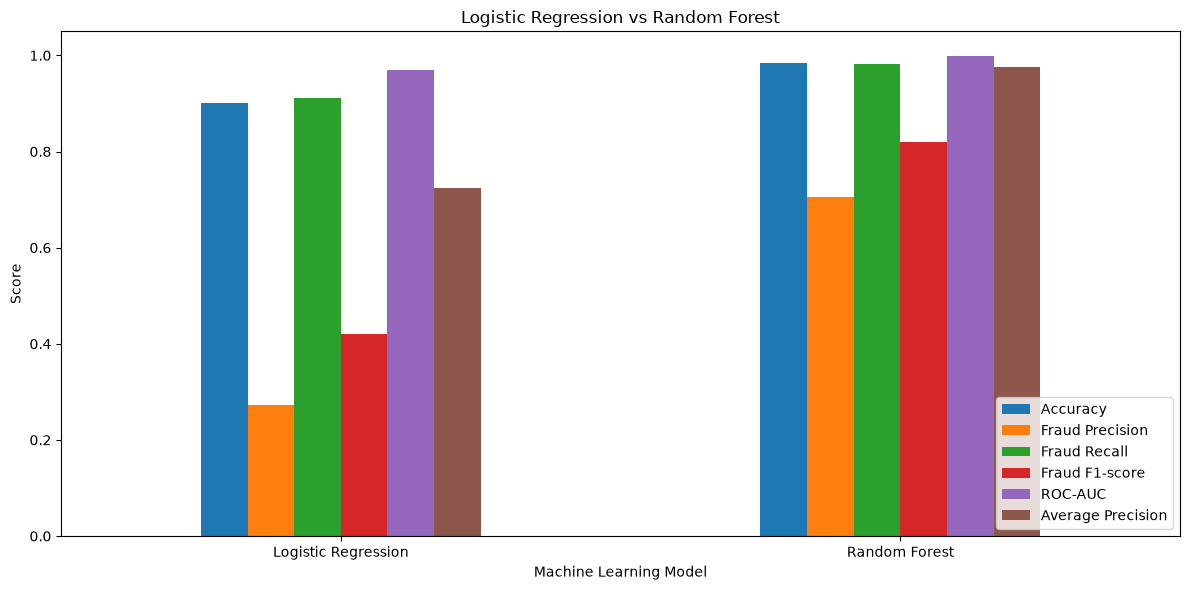

In [25]:

import pandas as pd
import matplotlib.pyplot as plt

comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [0.9004, 0.9831],
    "Fraud Precision": [0.2724, 0.7055],
    "Fraud Recall": [0.9117, 0.9811],
    "Fraud F1-score": [0.4195, 0.8208],
    "ROC-AUC": [0.9696, 0.9984],
    "Average Precision": [0.7241, 0.9767]
})

print("MODEL PERFORMANCE COMPARISON")
display(comparison.round(4))

comparison.set_index("Model").plot(
    kind="bar",
    figsize=(12, 6),
    ylim=(0, 1.05)
)

plt.title("Logistic Regression vs Random Forest")
plt.ylabel("Score")
plt.xlabel("Machine Learning Model")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


In [26]:

import pandas as pd
import numpy as np

rng = np.random.default_rng(123)
representative_parts = []
representative_size = 200_000

print("Creating a representative evaluation sample...")

for chunk in pd.read_csv(file_path, chunksize=100_000):
    chunk_sample = chunk.copy()

    chunk_sample["_random_key"] = rng.random(len(chunk_sample))

    representative_parts.append(
        chunk_sample.nsmallest(
            min(representative_size, len(chunk_sample)),
            "_random_key"
        )
    )

representative_df = pd.concat(
    representative_parts,
    ignore_index=True
)

representative_df = representative_df.nsmallest(
    representative_size,
    "_random_key"
).drop(columns=["_random_key"]).reset_index(drop=True)

print("\nREPRESENTATIVE SAMPLE SUMMARY")
print("Total transactions:", f"{len(representative_df):,}")
print("Fraudulent:", int(representative_df["isFraud"].sum()))
print("Legitimate:", int((representative_df["isFraud"] == 0).sum()))
print(
    "Fraud percentage:",
    round(representative_df["isFraud"].mean() * 100, 4),
    "%"
)


Creating a representative evaluation sample...

REPRESENTATIVE SAMPLE SUMMARY
Total transactions: 200,000
Fraudulent: 275
Legitimate: 199725
Fraud percentage: 0.1375 %


In [27]:

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

representative_features = representative_df[
    feature_columns
]

representative_target = representative_df["isFraud"]

print("LOGISTIC REGRESSION - REPRESENTATIVE EVALUATION")

log_pred = logistic_model.predict(representative_features)
log_prob = logistic_model.predict_proba(
    representative_features
)[:, 1]

print(classification_report(
    representative_target,
    log_pred,
    labels=[0, 1],
    target_names=["Legitimate", "Fraud"],
    digits=4,
    zero_division=0
))

print("ROC-AUC:", round(
    roc_auc_score(representative_target, log_prob), 4
))
print("Average Precision:", round(
    average_precision_score(representative_target, log_prob), 4
))
print("Confusion Matrix:")
print(confusion_matrix(
    representative_target,
    log_pred,
    labels=[0, 1]
))

print("\nRANDOM FOREST - REPRESENTATIVE EVALUATION")

rf_pred = rf_model.predict(representative_features)
rf_prob = rf_model.predict_proba(
    representative_features
)[:, 1]

print(classification_report(
    representative_target,
    rf_pred,
    labels=[0, 1],
    target_names=["Legitimate", "Fraud"],
    digits=4,
    zero_division=0
))

print("ROC-AUC:", round(
    roc_auc_score(representative_target, rf_prob), 4
))
print("Average Precision:", round(
    average_precision_score(representative_target, rf_prob), 4
))
print("Confusion Matrix:")
print(confusion_matrix(
    representative_target,
    rf_pred,
    labels=[0, 1]
))


LOGISTIC REGRESSION - REPRESENTATIVE EVALUATION
              precision    recall  f1-score   support

  Legitimate     0.9999    0.8996    0.9471    199725
       Fraud     0.0124    0.9164    0.0245       275

    accuracy                         0.8997    200000
   macro avg     0.5061    0.9080    0.4858    200000
weighted avg     0.9985    0.8997    0.9458    200000

ROC-AUC: 0.9695
Average Precision: 0.1992
Confusion Matrix:
[[179679  20046]
 [    23    252]]

RANDOM FOREST - REPRESENTATIVE EVALUATION
              precision    recall  f1-score   support

  Legitimate     1.0000    0.9835    0.9917    199725
       Fraud     0.0764    0.9927    0.1419       275

    accuracy                         0.9835    200000
   macro avg     0.5382    0.9881    0.5668    200000
weighted avg     0.9987    0.9835    0.9905    200000

ROC-AUC: 0.9995
Average Precision: 0.9156
Confusion Matrix:
[[196424   3301]
 [     2    273]]


In [28]:

import pandas as pd
import numpy as np

rng = np.random.default_rng(2026)
test_candidates = pd.DataFrame()
sample_size = 200_000
row_start = 0

print("Selecting an independent test sample...")

for chunk in pd.read_csv(file_path, chunksize=100_000):
    chunk["_row_id"] = np.arange(
        row_start,
        row_start + len(chunk)
    )
    row_start += len(chunk)

    chunk["_random_key"] = rng.random(len(chunk))

    test_candidates = pd.concat(
        [test_candidates, chunk],
        ignore_index=True
    )

    test_candidates = test_candidates.nsmallest(
        sample_size,
        "_random_key"
    ).reset_index(drop=True)

independent_test_df = (
    test_candidates
    .drop(columns=["_random_key"])
    .reset_index(drop=True)
)

print("\nINDEPENDENT TEST SAMPLE")
print("Total rows:", f"{len(independent_test_df):,}")
print("Fraudulent:", int(independent_test_df["isFraud"].sum()))
print(
    "Legitimate:",
    int((independent_test_df["isFraud"] == 0).sum())
)
print(
    "Fraud percentage:",
    round(independent_test_df["isFraud"].mean() * 100, 4),
    "%"
)


Selecting an independent test sample...

INDEPENDENT TEST SAMPLE
Total rows: 200,000
Fraudulent: 296
Legitimate: 199704
Fraud percentage: 0.148 %


In [29]:

import pandas as pd
import numpy as np

# Identify the rows reserved for independent testing
test_row_ids = set(independent_test_df["_row_id"].astype(int))

# Store training candidates separately
rng = np.random.default_rng(42)
training_candidates = pd.DataFrame()

row_start = 0
fraud_count = 0
legitimate_sample_size = 200_000

print("Preparing training data without test transactions...")

for chunk in pd.read_csv(file_path, chunksize=100_000):
    chunk["_row_id"] = np.arange(
        row_start, row_start + len(chunk)
    )
    row_start += len(chunk)

    # Exclude every transaction reserved for testing
    chunk = chunk[~chunk["_row_id"].isin(test_row_ids)].copy()

    # Keep all remaining fraudulent transactions
    fraud_rows = chunk[chunk["isFraud"] == 1].copy()
    fraud_count += len(fraud_rows)

    # Randomly sample legitimate transactions
    legitimate_rows = chunk[chunk["isFraud"] == 0].copy()
    legitimate_rows["_random_key"] = rng.random(len(legitimate_rows))

    training_candidates = pd.concat(
        [training_candidates, legitimate_rows],
        ignore_index=True
    )

    training_candidates = (
        training_candidates
        .nsmallest(legitimate_sample_size, "_random_key")
        .reset_index(drop=True)
    )

    # Collect fraud rows outside the test sample
    if "fraud_rows_list" not in globals():
        fraud_rows_list = []

    fraud_rows_list.append(fraud_rows)

# Combine the selected legitimate and fraudulent transactions
legitimate_train = training_candidates.drop(
    columns=["_random_key"]
)

fraud_train = pd.concat(fraud_rows_list, ignore_index=True)

train_df = pd.concat(
    [legitimate_train, fraud_train],
    ignore_index=True
).drop(columns=["_row_id"])

# Clean up temporary variables
del training_candidates, legitimate_train, fraud_train, fraud_rows_list

print("\nTRAINING DATA SUMMARY")
print("Total training rows:", f"{len(train_df):,}")
print("Fraudulent transactions:", int(train_df["isFraud"].sum()))
print(
    "Legitimate transactions:",
    int((train_df["isFraud"] == 0).sum())
)
print("Training fraud rate:", round(train_df["isFraud"].mean() * 100, 3), "%")


Preparing training data without test transactions...

TRAINING DATA SUMMARY
Total training rows: 207,917
Fraudulent transactions: 7917
Legitimate transactions: 200000
Training fraud rate: 3.808 %


In [30]:

from sklearn.model_selection import train_test_split

# Select the input features
feature_columns = [
    "step",
    "type",
    "amount",
    "oldbalanceOrg",
    "oldbalanceDest"
]

X_train = train_df[feature_columns].copy()
y_train = train_df["isFraud"].copy()

# Prepare the independent test features and target
X_test = independent_test_df[feature_columns].copy()
y_test = independent_test_df["isFraud"].copy()

print("TRAINING SET")
print("Rows:", f"{len(X_train):,}")
print("Fraud cases:", int(y_train.sum()))

print("\nINDEPENDENT TEST SET")
print("Rows:", f"{len(X_test):,}")
print("Fraud cases:", int(y_test.sum()))

# Confirm that the test data has not been altered
print("\nTest fraud rate:", round(y_test.mean() * 100, 4), "%")


TRAINING SET
Rows: 207,917
Fraud cases: 7917

INDEPENDENT TEST SET
Rows: 200,000
Fraud cases: 296

Test fraud rate: 0.148 %


In [31]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Identify numeric and categorical features
numeric_features = [
    "step", "amount", "oldbalanceOrg", "oldbalanceDest"
]
categorical_features = ["type"]

# Prepare preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), numeric_features),
        ("categorical", OneHotEncoder(handle_unknown="ignore"),
         categorical_features)
    ]
)

# Build Logistic Regression model
logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

# Build Random Forest model
rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        max_depth=15,
        min_samples_leaf=2,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    ))
])

# Train both models using training data only
print("Training Logistic Regression...")
logistic_model.fit(X_train, y_train)
print("Logistic Regression training complete.")

print("\nTraining Random Forest...")
rf_model.fit(X_train, y_train)
print("Random Forest training complete.")

print("\nBoth models have been retrained successfully!")


Training Logistic Regression...
Logistic Regression training complete.

Training Random Forest...
Random Forest training complete.

Both models have been retrained successfully!


In [32]:

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    roc_auc_score,
    average_precision_score
)

# Store the trained models
models = {
    "Logistic Regression": logistic_model,
    "Random Forest": rf_model
}

results = []

for model_name, model in models.items():
    print("\n" + "=" * 60)
    print(model_name.upper())
    print("=" * 60)

    # Predict transaction classes
    y_pred = model.predict(X_test)

    # Predict fraud probabilities
    y_prob = model.predict_proba(X_test)[:, 1]

    # Display classification report
    print("\nClassification Report:")
    print(classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["Legitimate", "Fraud"],
        zero_division=0
    ))

    # Display confusion matrix
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    print("Confusion Matrix:")
    print(cm)

    # Calculate performance metrics
    accuracy = accuracy_score(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, y_prob)
    avg_precision = average_precision_score(y_test, y_prob)

    results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "ROC-AUC": roc_auc,
        "Average Precision": avg_precision
    })

    print(f"\nAccuracy: {accuracy:.4f}")
    print(f"ROC-AUC: {roc_auc:.4f}")
    print(f"Average Precision: {avg_precision:.4f}")

# Compare both models
results_df = pd.DataFrame(results)

print("\nFINAL MODEL COMPARISON")
print(results_df.round(4).to_string(index=False))



LOGISTIC REGRESSION

Classification Report:
              precision    recall  f1-score   support

  Legitimate       1.00      0.90      0.95    199704
       Fraud       0.01      0.92      0.03       296

    accuracy                           0.90    200000
   macro avg       0.51      0.91      0.49    200000
weighted avg       1.00      0.90      0.95    200000

Confusion Matrix:
[[180726  18978]
 [    24    272]]

Accuracy: 0.9050
ROC-AUC: 0.9721
Average Precision: 0.2267

RANDOM FOREST

Classification Report:
              precision    recall  f1-score   support

  Legitimate       1.00      0.98      0.99    199704
       Fraud       0.09      0.98      0.16       296

    accuracy                           0.98    200000
   macro avg       0.54      0.98      0.57    200000
weighted avg       1.00      0.98      0.99    200000

Confusion Matrix:
[[196583   3121]
 [     5    291]]

Accuracy: 0.9844
ROC-AUC: 0.9991
Average Precision: 0.8816

FINAL MODEL COMPARISON
            

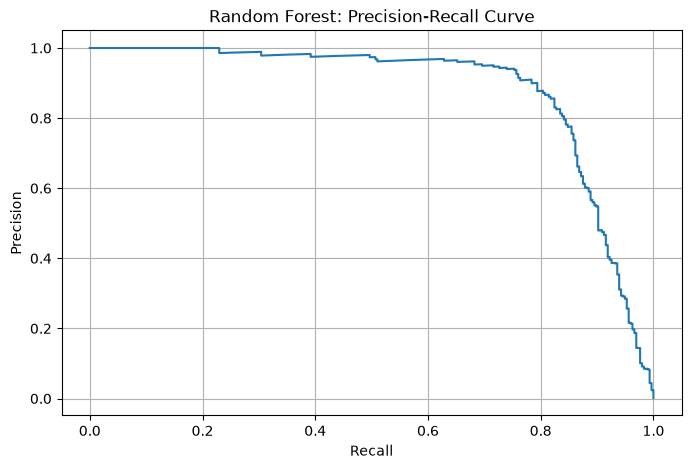

Minimum predicted fraud probability: 0.0
Maximum predicted fraud probability: 1.0


In [33]:

from sklearn.metrics import precision_recall_curve
import matplotlib.pyplot as plt

# Obtain fraud probabilities from the independent test set
rf_probabilities = rf_model.predict_proba(X_test)[:, 1]

# Calculate precision and recall across different thresholds
precision_values, recall_values, thresholds = precision_recall_curve(
    y_test, rf_probabilities
)

# Plot the precision-recall curve
plt.figure(figsize=(8, 5))
plt.plot(recall_values, precision_values)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Random Forest: Precision-Recall Curve")
plt.grid(True)
plt.show()

print("Minimum predicted fraud probability:",
      round(float(rf_probabilities.min()), 6))
print("Maximum predicted fraud probability:",
      round(float(rf_probabilities.max()), 6))


In [34]:

from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd

# Test several possible decision thresholds
thresholds_to_test = [
    0.10, 0.20, 0.30, 0.40, 0.50,
    0.60, 0.70, 0.80, 0.90
]

threshold_results = []

for threshold in thresholds_to_test:
    # Classify transactions using the selected threshold
    y_pred_threshold = (
        rf_probabilities >= threshold
    ).astype(int)

    # Calculate confusion matrix
    tn, fp, fn, tp = confusion_matrix(
        y_test, y_pred_threshold, labels=[0, 1]
    ).ravel()

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_test, y_pred_threshold, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred_threshold, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, y_pred_threshold, zero_division=0
        ),
        "True Positives": tp,
        "Missed Fraud": fn,
        "False Alarms": fp,
        "Total Alerts": tp + fp
    })

threshold_df = pd.DataFrame(threshold_results)

print("RANDOM FOREST THRESHOLD COMPARISON")
print(threshold_df.round(4).to_string(index=False))


RANDOM FOREST THRESHOLD COMPARISON
 Threshold  Precision  Recall  F1-score  True Positives  Missed Fraud  False Alarms  Total Alerts
       0.1     0.0232  1.0000    0.0453             296             0         12490         12786
       0.2     0.0341  0.9966    0.0660             295             1          8355          8650
       0.3     0.0460  0.9932    0.0879             294             2          6096          6390
       0.4     0.0608  0.9932    0.1147             294             2          4538          4832
       0.5     0.0853  0.9831    0.1570             291             5          3121          3412
       0.6     0.1377  0.9764    0.2413             289             7          1810          2099
       0.7     0.2575  0.9527    0.4055             282            14           813          1095
       0.8     0.5693  0.8885    0.6939             263            33           199           462
       0.9     0.8255  0.8311    0.8283             246            50            52

In [35]:

from sklearn.metrics import classification_report, confusion_matrix
import joblib

# Select our candidate threshold
chosen_threshold = 0.80

# Make predictions using the Random Forest probabilities
rf_predictions_080 = (
    rf_probabilities >= chosen_threshold
).astype(int)

print("RANDOM FOREST AT THRESHOLD 0.80")
print("\nClassification report:")
print(classification_report(
    y_test,
    rf_predictions_080,
    labels=[0, 1],
    target_names=["Legitimate", "Fraud"],
    zero_division=0
))

print("Confusion matrix:")
print(confusion_matrix(
    y_test,
    rf_predictions_080,
    labels=[0, 1]
))

# Save the trained model and threshold for later use
joblib.dump(
    {
        "model": rf_model,
        "threshold": chosen_threshold
    },
    "fraud_detection_random_forest.joblib"
)

print("\nModel and threshold saved successfully.")


RANDOM FOREST AT THRESHOLD 0.80

Classification report:
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00    199704
       Fraud       0.57      0.89      0.69       296

    accuracy                           1.00    200000
   macro avg       0.78      0.94      0.85    200000
weighted avg       1.00      1.00      1.00    200000

Confusion matrix:
[[199505    199]
 [    33    263]]

Model and threshold saved successfully.


In [36]:

import joblib
import pandas as pd

# Load our trained model and selected threshold
saved_model = joblib.load(
    "fraud_detection_random_forest.joblib"
)

fraud_model = saved_model["model"]
fraud_threshold = saved_model["threshold"]

print("Fraud detection system loaded successfully!")
print("Model: Random Forest")
print("Decision threshold:", fraud_threshold)
print("Ready to analyse a transaction.")


Fraud detection system loaded successfully!
Model: Random Forest
Decision threshold: 0.8
Ready to analyse a transaction.


In [37]:

# Example transaction for demonstration
transaction = pd.DataFrame([{
    "step": 100,
    "type": "TRANSFER",
    "amount": 50000.0,
    "oldbalanceOrg": 50000.0,
    "oldbalanceDest": 0.0
}])

# Predict fraud probability
fraud_probability = fraud_model.predict_proba(
    transaction
)[0, 1]

# Apply our selected threshold
prediction = (
    "Potentially Fraudulent"
    if fraud_probability >= fraud_threshold
    else "Likely Legitimate"
)

print("TRANSACTION ANALYSIS")
print("-" * 35)
print("Transaction type:", transaction.loc[0, "type"])
print("Amount:", transaction.loc[0, "amount"])
print(
    "Estimated fraud probability:",
    f"{fraud_probability:.2%}"
)
print("Model decision:", prediction)
print("-" * 35)
print("This is a model prediction, not proof of fraud.")


TRANSACTION ANALYSIS
-----------------------------------
Transaction type: TRANSFER
Amount: 50000.0
Estimated fraud probability: 97.54%
Model decision: Potentially Fraudulent
-----------------------------------
This is a model prediction, not proof of fraud.


In [40]:

%pip show streamlit


Name: streamlit
Version: 1.58.0
Summary: A faster way to build and share data apps
Home-page: https://streamlit.io
Author: 
Author-email: Snowflake Inc <hello@streamlit.io>
License-Expression: Apache-2.0
Location: C:\Users\primr\anaconda3\Lib\site-packages
Requires: altair, anyio, blinker, cachetools, click, gitpython, httptools, itsdangerous, numpy, packaging, pandas, pillow, protobuf, pyarrow, python-multipart, requests, starlette, tenacity, toml, typing-extensions, uvicorn, watchdog, websockets
Required-by: 
Note: you may need to restart the kernel to use updated packages.
